# Stationarity test results

Exploratory analysis of the CSVs produced by `experiments/stationarity_tests.py`.

**Files expected:**
- `../experiments/stationarity_results/summary.csv`
- `../experiments/stationarity_results/per_node.csv`

In [33]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

RESULTS_DIR = "../experiments/stationarity_results"
ALPHA_ADF   = 0.05   # p < α → ADF calls stationary
ALPHA_KPSS  = 0.05   # p < α → KPSS calls non-stationary
ALPHA_BREAK = 0.05   # threshold for structural-break tests

summary  = pd.read_csv(f"{RESULTS_DIR}/summary.csv")
per_node = pd.read_csv(f"{RESULTS_DIR}/per_node.csv")

print(f"Datasets : {len(summary)}")
print(f"Node rows: {len(per_node)}")
print(f"\nSummary columns:\n{list(summary.columns)}")
print(f"\nPer-node columns:\n{list(per_node.columns)}")

Datasets : 5
Node rows: 28

Summary columns:
['dataset_label', 'description', 'generator', 'scenario', 'T', 'N', 'switch_times', 'adf_pvalue_mean', 'adf_pvalue_max', 'adf_overall_call', 'kpss_pvalue_mean', 'kpss_pvalue_min', 'kpss_overall_call', 'cusum_sq_stat_mean', 'cusum_sq_overall_call', 'delta_mean_mean', 'delta_mean_max', 'delta_var_pct_mean', 'delta_var_pct_max', 'delta_corr', 'andrews_supF', 'andrews_break_t', 'andrews_pvalue', 'andrews_call', 'edivisive_stat', 'edivisive_pvalue', 'edivisive_call', 'ruptures_breaks', 'ruptures_n_breaks']

Per-node columns:
['dataset_label', 'description', 'generator', 'scenario', 'T', 'N', 'switch_times', 'node', 'adf_statistic', 'adf_pvalue', 'adf_call', 'kpss_statistic', 'kpss_pvalue', 'kpss_call', 'cusum_sq_stat', 'cusum_sq_pvalue', 'cusum_sq_call', 'delta_mean', 'delta_var_pct']


## Summary table

In [34]:
display_cols = [
    "dataset_label", "generator", "scenario", "T", "N",
    "adf_overall_call", "kpss_overall_call",
    "delta_mean_mean", "delta_var_pct_mean", "delta_corr",
]
summary[display_cols].style \
    .set_caption("One row per dataset — overall stationarity verdicts and structural-change metrics") \
    .format({
        "delta_mean_mean":    "{:.3f}",
        "delta_var_pct_mean": "{:+.1f}%",
        "delta_corr":         "{:.3f}",
    }) \
    .background_gradient(subset=["delta_corr"], cmap="YlOrRd")

,dataset_label,generator,scenario,T,N,adf_overall_call,kpss_overall_call,delta_mean_mean,delta_var_pct_mean,delta_corr
0,sinusoid_weak_switch,sinusoid,sinusoid,400,5,stationary,stationary,0.013,+0.1%,0.818
1,sinusoid_strong_switch,sinusoid,sinusoid,400,5,stationary,mixed (4/5 stationary),0.008,+0.1%,0.745
2,var_modular_to_hub,var,modular_to_hub,400,6,stationary,stationary,0.015,-17.0%,0.999
3,var_critical_slowing,var,critical_slowing,400,6,stationary,stationary,0.014,+37.1%,1.708
4,var_sign_flip,var,sign_flip,400,6,stationary,stationary,0.006,+7.9%,3.542


## Structural-break tests (summary-level)

Each row is one dataset.  Tests:
- **CUSUM-sq** (per-node, aggregated): fraction of nodes where block-bootstrap p < α
- **Chow VAR F-test**: OLS per equation, F-statistic at the known midpoint break
- **E-divisive**: multivariate energy distance, permutation p-value
- **Ruptures KernelCPD (RBF)**: number of detected change-points under BIC penalty

In [35]:
break_cols = [
    "andrews_supF", "andrews_break_t", "andrews_pvalue", "andrews_call",
    "edivisive_stat", "edivisive_pvalue", "edivisive_call",
    "ruptures_n_breaks",
]
available = [c for c in break_cols if c in summary.columns]

show = ["dataset_label"] + available

fmt = {}
if "andrews_supF"     in available: fmt["andrews_supF"]     = "{:.2f}"
if "andrews_pvalue"   in available: fmt["andrews_pvalue"]   = "{:.4f}"
if "edivisive_stat"   in available: fmt["edivisive_stat"]   = "{:.3f}"
if "edivisive_pvalue" in available: fmt["edivisive_pvalue"] = "{:.4f}"

def _colour_call(val):
    if str(val) in ("break detected", "change detected"): return "background-color: #f7c5c5"
    if str(val) in ("no break", "no change"):             return "background-color: #c8f7c5"
    return ""

call_cols = [c for c in ["andrews_call", "edivisive_call"] if c in available]

summary[show].style \
    .set_caption("Structural-break test results (one row per dataset)") \
    .format(fmt) \
    .map(_colour_call, subset=call_cols)

,dataset_label,andrews_supF,andrews_break_t,andrews_pvalue,andrews_call,edivisive_stat,edivisive_pvalue,edivisive_call,ruptures_n_breaks
0,sinusoid_weak_switch,4.13,119,0.0000,break detected,0.022,0.8417,no change,0
1,sinusoid_strong_switch,4.86,121,0.0000,break detected,0.018,0.9479,no change,0
2,var_modular_to_hub,4.07,194,0.0000,break detected,0.015,0.1784,no change,0
3,var_critical_slowing,22.23,200,0.0000,break detected,0.050,0.0020,change detected,0
4,var_sign_flip,1254.32,200,0.0000,break detected,0.078,0.0000,change detected,0


## Per-node ADF / KPSS p-values  
Colour: green = stationary, red = non-stationary.

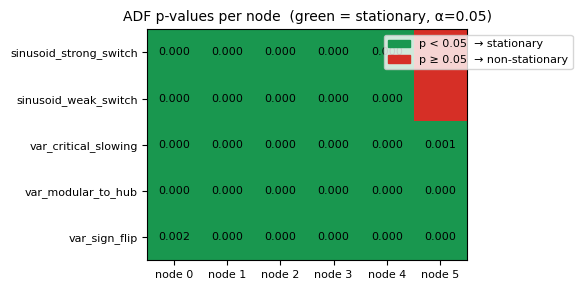

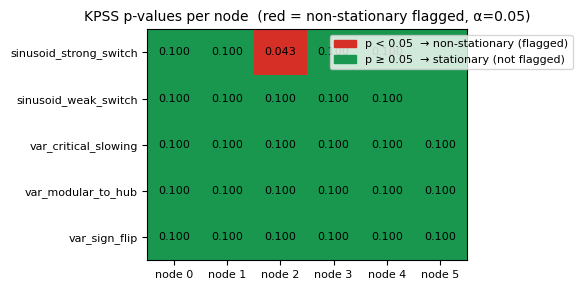

In [36]:
def pvalue_heatmap(per_node, col_pval, call_direction,
                   title, alpha=0.05, row_height=0.6):
    """
    call_direction : 'low_is_detected' (ADF: p<α → stationary)
                     'low_is_nonstat'  (KPSS: p<α → non-stationary)
    """
    pivot = per_node.pivot_table(
        index="dataset_label", columns="node", values=col_pval, aggfunc="first"
    )
    datasets = pivot.index.tolist()
    n_nodes  = pivot.shape[1]

    fig, ax = plt.subplots(figsize=(max(6, n_nodes * 1.1),
                                    max(2, len(datasets) * row_height)))

    if call_direction == "low_is_detected":
        colour_arr = np.where(pivot.values < alpha, 0.9, 0.1)
        cmap = "RdYlGn"
    else:
        colour_arr = np.where(pivot.values < alpha, 0.1, 0.9)
        cmap = "RdYlGn"

    ax.imshow(colour_arr, cmap=cmap, vmin=0, vmax=1, aspect="auto")

    for i, ds in enumerate(datasets):
        for j, node in enumerate(pivot.columns):
            pv = pivot.loc[ds, node]
            if pd.notna(pv):
                ax.text(j, i, f"{pv:.3f}", ha="center", va="center", fontsize=8)

    ax.set_xticks(range(n_nodes))
    ax.set_xticklabels([f"node {c}" for c in pivot.columns], fontsize=8)
    ax.set_yticks(range(len(datasets)))
    ax.set_yticklabels(datasets, fontsize=8)
    ax.set_title(title, fontsize=10)

    if call_direction == "low_is_detected":
        patches = [
            mpatches.Patch(color=plt.cm.RdYlGn(0.9), label=f"p < {alpha}  → stationary"),
            mpatches.Patch(color=plt.cm.RdYlGn(0.1), label=f"p ≥ {alpha}  → non-stationary"),
        ]
    else:
        patches = [
            mpatches.Patch(color=plt.cm.RdYlGn(0.1), label=f"p < {alpha}  → non-stationary (flagged)"),
            mpatches.Patch(color=plt.cm.RdYlGn(0.9), label=f"p ≥ {alpha}  → stationary (not flagged)"),
        ]
    ax.legend(handles=patches, loc="upper right", bbox_to_anchor=(1.35, 1.0), fontsize=8)
    plt.tight_layout()
    plt.show()

pvalue_heatmap(per_node, "adf_pvalue",  "low_is_detected",
               f"ADF p-values per node  (green = stationary, α={ALPHA_ADF})")
pvalue_heatmap(per_node, "kpss_pvalue", "low_is_nonstat",
               f"KPSS p-values per node  (red = non-stationary flagged, α={ALPHA_KPSS})")

## CUSUM-of-squares per node

Inclan-Tiao (1994) statistic with block-bootstrap p-value.  
Red = structural break in variance detected (p < α).

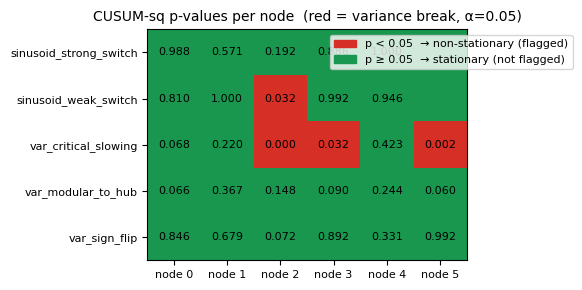

In [37]:
if "cusum_sq_pvalue" in per_node.columns:
    pvalue_heatmap(per_node, "cusum_sq_pvalue", "low_is_nonstat",
                   f"CUSUM-sq p-values per node  (red = variance break, α={ALPHA_BREAK})",
                   alpha=ALPHA_BREAK)
else:
    print("cusum_sq_pvalue not found in per_node.csv — re-run stationarity_tests.py")

## Test sensitivity per dataset
For each dataset: what fraction of nodes does each test flag?  
High bar = test detects something.  For `modular_to_hub` we expect all bars ≈ 0 except ΔCorr / E-divisive.

In [38]:
def frac_flagged(group):
    n = len(group)
    d = {
        "ADF: frac non-stationary":  (group["adf_pvalue"]  >= ALPHA_ADF).sum()  / n,
        "KPSS: frac non-stationary": (group["kpss_pvalue"] <  ALPHA_KPSS).sum() / n,
        "Δmean (mean)": group["delta_mean"].mean(),
        "|Δvar%| (mean)": group["delta_var_pct"].abs().mean(),
    }
    if "cusum_sq_pvalue" in group.columns:
        d["CUSUM-sq: frac break"] = (group["cusum_sq_pvalue"] < ALPHA_BREAK).sum() / n
    return pd.Series(d)

node_flags = per_node.groupby("dataset_label").apply(frac_flagged)

# Add summary-level multivariate metrics
smry_idx = summary.set_index("dataset_label")
merge_cols = ["delta_corr"]
if "edivisive_pvalue" in smry_idx.columns:
    # Binary: E-divisive detects break
    smry_idx["E-div: detected"] = (smry_idx["edivisive_pvalue"] < ALPHA_BREAK).astype(float)
    merge_cols.append("E-div: detected")

node_flags = node_flags.join(smry_idx[merge_cols])

dc_max = node_flags["delta_corr"].max()
node_flags["ΔCorr (normalised)"] = node_flags["delta_corr"] / (dc_max + 1e-9)

plot_cols = [
    "ADF: frac non-stationary",
    "KPSS: frac non-stationary",
    "Δmean (mean)",
    "|Δvar%| (mean)",
    "ΔCorr (normalised)",
]
if "CUSUM-sq: frac break" in node_flags.columns:
    plot_cols.insert(2, "CUSUM-sq: frac break")
if "E-div: detected" in node_flags.columns:
    plot_cols.insert(-1, "E-div: detected")

colours = ["#e07b54", "#5c8ecc", "#c0392b", "#6abf69", "#f2c94c", "#27ae60", "#9b59b6"]


node_flags[plot_cols + ["delta_corr"]].round(3)

C:\Users\brennerm\AppData\Local\Temp\ipykernel_1236\4128210450.py:13: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  node_flags = per_node.groupby("dataset_label").apply(frac_flagged)


,ADF: frac non-stationary,KPSS: frac non-stationary,CUSUM-sq: frac break,Δmean (mean),|Δvar%| (mean),E-div: detected,ΔCorr (normalised),delta_corr
dataset_label,,,,,,,,
sinusoid_strong_switch,0.0,0.2,0.0,0.008,1.942,0.0,0.210,0.745
sinusoid_weak_switch,0.0,0.0,0.2,0.013,3.703,0.0,0.231,0.818
var_critical_slowing,0.0,0.0,0.5,0.014,37.134,1.0,0.482,1.708
var_modular_to_hub,0.0,0.0,0.0,0.015,17.004,0.0,0.282,0.999
var_sign_flip,0.0,0.0,0.0,0.006,11.690,1.0,1.000,3.542


## Multivariate structural-break tests (Chow, E-divisive, Ruptures)

These tests work on the full multivariate time series — they can detect changes in cross-node correlation even when univariate tests fail.

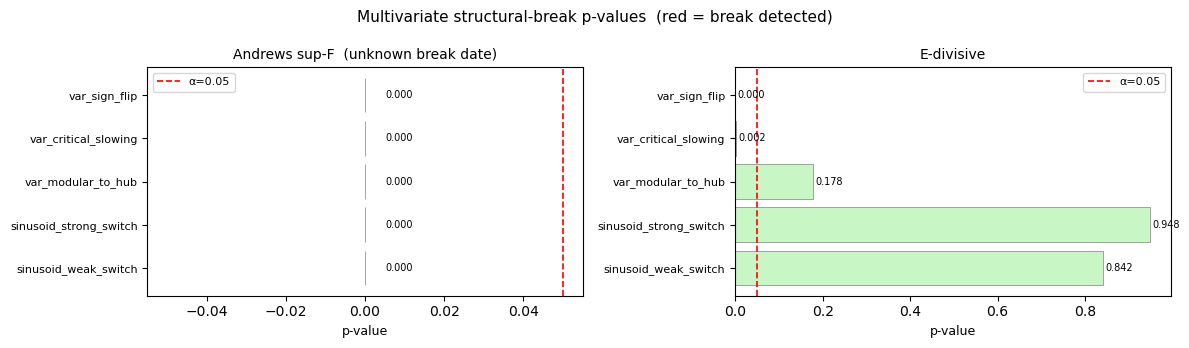

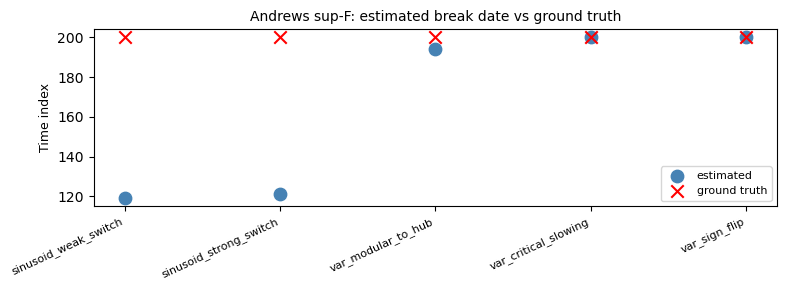

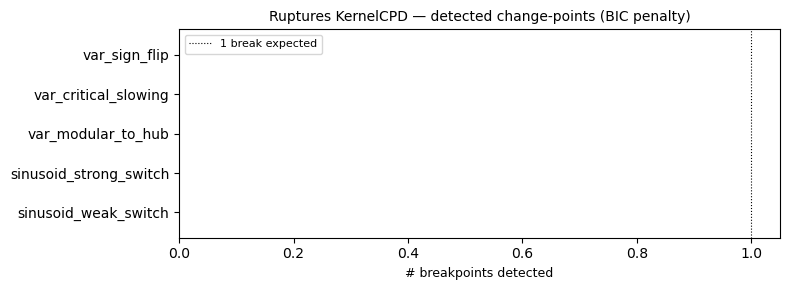

In [39]:
mv_tests = [
    ("andrews_pvalue", "andrews_call", "Andrews sup-F  (unknown break date)", "low_is_break"),
    ("edivisive_pvalue", "edivisive_call", "E-divisive", "low_is_break"),
]

available_mv = [(pv, cc, label, d) for pv, cc, label, d in mv_tests if pv in summary.columns]

if not available_mv:
    print("No multivariate test columns found — re-run stationarity_tests.py")
else:
    n_tests = len(available_mv)
    fig, axes = plt.subplots(1, n_tests, figsize=(6 * n_tests, 3.5), squeeze=False)

    for ax, (pv_col, cc_col, label, _) in zip(axes[0], available_mv):
        vals  = summary[pv_col].values
        calls = summary[cc_col].values if cc_col in summary.columns else [""] * len(vals)
        ds    = summary["dataset_label"].values

        colours_bar = ["#f7c5c5" if str(c) in ("break detected", "change detected") else "#c8f7c5"
                       for c in calls]
        ax.barh(range(len(ds)), vals, color=colours_bar, edgecolor="grey", lw=0.5)
        ax.axvline(ALPHA_BREAK, color="red", lw=1.2, linestyle="--",
                   label=f"α={ALPHA_BREAK}")
        ax.set_yticks(range(len(ds)))
        ax.set_yticklabels(ds, fontsize=8)
        ax.set_xlabel("p-value", fontsize=9)
        ax.set_title(label, fontsize=10)
        ax.legend(fontsize=8)

        for i, v in enumerate(vals):
            if pd.notna(v):
                ax.text(v + 0.005, i, f"{v:.3f}", va="center", fontsize=7)

    plt.suptitle("Multivariate structural-break p-values  (red = break detected)", fontsize=11)
    plt.tight_layout()
    plt.show()

# Andrews: also show the estimated break date vs ground truth
if "andrews_break_t" in summary.columns and "switch_times" in summary.columns:
    fig, ax = plt.subplots(figsize=(8, 3))
    for i, row in summary.iterrows():
        true_t = int(str(row["switch_times"]).split(";")[0]) if pd.notna(row["switch_times"]) else None
        est_t  = row["andrews_break_t"]
        ax.scatter(i, est_t,  marker="o", color="steelblue", s=80, zorder=3, label="estimated" if i == 0 else "")
        if true_t is not None:
            ax.scatter(i, true_t, marker="x", color="red",      s=80, zorder=3, label="ground truth" if i == 0 else "")
    ax.set_xticks(range(len(summary)))
    ax.set_xticklabels(summary["dataset_label"], rotation=25, ha="right", fontsize=8)
    ax.set_ylabel("Time index", fontsize=9)
    ax.set_title("Andrews sup-F: estimated break date vs ground truth", fontsize=10)
    ax.legend(fontsize=8)
    plt.tight_layout()
    plt.show()

# Ruptures: number of detected breakpoints
if "ruptures_n_breaks" in summary.columns:
    fig, ax = plt.subplots(figsize=(8, 3))
    n_breaks = summary["ruptures_n_breaks"].fillna(0).astype(int)
    ax.barh(summary["dataset_label"], n_breaks,
            color=["#f7c5c5" if n > 0 else "#c8f7c5" for n in n_breaks],
            edgecolor="grey", lw=0.5)
    ax.axvline(1, color="black", lw=0.8, linestyle=":", label="1 break expected")
    ax.set_xlabel("# breakpoints detected", fontsize=9)
    ax.set_title("Ruptures KernelCPD — detected change-points (BIC penalty)", fontsize=10)
    ax.legend(fontsize=8)
    plt.tight_layout()
    plt.show()

## Δmean and Δvar distributions (per node, per dataset)

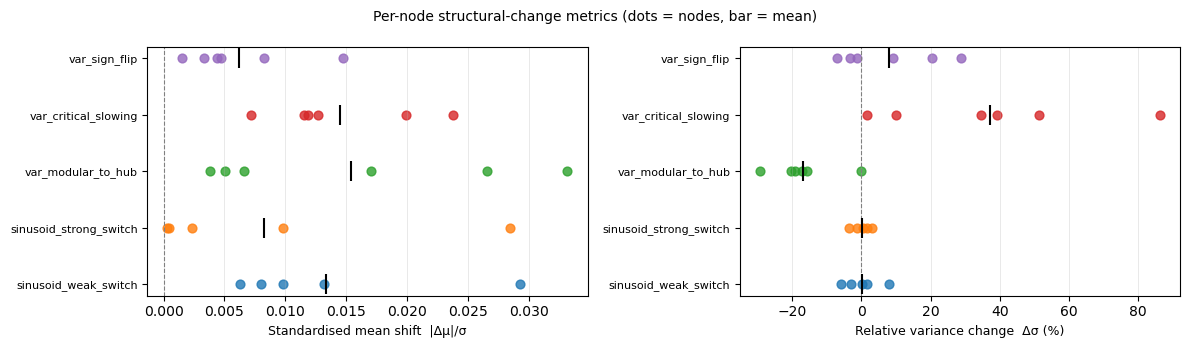

In [40]:
datasets = per_node["dataset_label"].unique()
n_ds = len(datasets)

fig, axes = plt.subplots(1, 2, figsize=(12, max(3, n_ds * 0.5 + 1)))

for ax, col, xlabel in [
    (axes[0], "delta_mean",    "Standardised mean shift  |Δμ|/σ"),
    (axes[1], "delta_var_pct", "Relative variance change  Δσ (%)"),
]:
    for i, ds in enumerate(datasets):
        vals = per_node.loc[per_node["dataset_label"] == ds, col].dropna()
        ax.scatter(vals, [i] * len(vals), s=40, alpha=0.8)
        ax.scatter(vals.mean(), i, marker="|", s=200, color="black", zorder=5)

    ax.set_yticks(range(n_ds))
    ax.set_yticklabels(datasets, fontsize=8)
    ax.set_xlabel(xlabel, fontsize=9)
    ax.axvline(0, color="grey", lw=0.8, linestyle="--")
    ax.grid(axis="x", lw=0.5, alpha=0.4)

fig.suptitle("Per-node structural-change metrics (dots = nodes, bar = mean)", fontsize=10)
plt.tight_layout()
plt.show()

## Raw per-node table  
Full per-node CSV for inspection and filtering.

In [21]:
# Filter to a specific dataset if needed — set to None for all
FILTER_DATASET = None  # e.g. "var_modular_to_hub"

df = per_node if FILTER_DATASET is None else per_node[per_node["dataset_label"] == FILTER_DATASET]

show_cols = ["dataset_label", "node",
             "adf_pvalue", "adf_call",
             "kpss_pvalue", "kpss_call",
             "delta_mean", "delta_var_pct"]

# Add CUSUM-sq if present
if "cusum_sq_pvalue" in df.columns:
    show_cols += ["cusum_sq_pvalue", "cusum_sq_call"]

show_cols = [c for c in show_cols if c in df.columns]
call_cols = [c for c in show_cols if c.endswith("_call")]

def _colour_call(val):
    if val in ("stationary", "no-break"):     return "background-color: #c8f7c5"
    if val in ("non-stationary", "break"):    return "background-color: #f7c5c5"
    return ""

fmt = {
    "adf_pvalue":       "{:.4f}",
    "kpss_pvalue":      "{:.4f}",
    "delta_mean":       "{:.4f}",
    "delta_var_pct":    "{:+.2f}%",
}
if "cusum_sq_pvalue" in show_cols:
    fmt["cusum_sq_pvalue"] = "{:.4f}"

df[show_cols].style \
    .map(_colour_call, subset=call_cols) \
    .format(fmt)

,dataset_label,node,adf_pvalue,adf_call,kpss_pvalue,kpss_call,delta_mean,delta_var_pct,cusum_sq_pvalue,cusum_sq_call
0,sinusoid_weak_switch,0,0.0000,stationary,0.1000,stationary,0.0098,+8.01%,0.8096,stable variance
1,sinusoid_weak_switch,1,0.0000,stationary,0.1000,stationary,0.0080,+1.54%,1.0000,stable variance
2,sinusoid_weak_switch,2,0.0000,stationary,0.1000,stationary,0.0132,-5.94%,0.0321,unstable variance
3,sinusoid_weak_switch,3,0.0000,stationary,0.1000,stationary,0.0293,-2.98%,0.9920,stable variance
4,sinusoid_weak_switch,4,0.0000,stationary,0.1000,stationary,0.0063,+0.04%,0.9459,stable variance
5,sinusoid_strong_switch,0,0.0000,stationary,0.1000,stationary,0.0005,+0.50%,0.9880,stable variance
6,sinusoid_strong_switch,1,0.0000,stationary,0.1000,stationary,0.0098,+2.96%,0.5711,stable variance
7,sinusoid_strong_switch,2,0.0000,stationary,0.0429,non-stationary,0.0003,-1.21%,0.1924,stable variance
8,sinusoid_strong_switch,3,0.0000,stationary,0.1000,stationary,0.0284,-3.50%,0.8858,stable variance
9,sinusoid_strong_switch,4,0.0000,stationary,0.1000,stationary,0.0023,+1.54%,1.0000,stable variance
